#### 02B · Selección de PCs pensando en los temporales
Hasta ahora las PCs se eligieron por la importancia del XGB y se validaron con correlación / R², métricas que dominan las horas normales. Aquí:
1. **Dos rankings lineales** (más estables que la ganancia del XGB), ajustados solo en 1985–2015 con pliegues por años:
   - **Lasso** → qué PCs explican la **media**.
   - **Regresión cuantílica (τ = 0,95) con L1** → qué PCs empujan el **borde alto** (temporales). Usa todas las horas: no trunca por y.
2. **Curva de selección** para cada ranking: XGB OOF (GroupKFold por años, 1985–2015) con k PCs, midiendo **corr OOF** y **picos de temporal** (ŷ/obs en los temporales > q99).
3. **Test 2016–2025** de los conjuntos elegidos frente a la selección actual, con las mismas métricas y Juliette.

El test no se toca hasta el paso 3.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = os.environ["OPENBLAS_NUM_THREADS"] = "1"   # arriba del todo, antes de importar numpy (reinicia el kernel)

import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from utils.pit.piece_wise_marginal import PiecewiseMarginal, to_normal, from_normal
from utils.pit.empirical_marginal import EmpiricalPiece
from utils.pit.gpd_marginal import GPDPiece
from utils.tv_var.harmonic_standardizer import HarmonicStandardizer

from sklearn.linear_model import LassoCV, QuantileRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from scipy.signal import find_peaks

from xgboost import XGBRegressor

In [2]:
#### Entradas
PUNTO = "inputs/waves_bulk_p102.csv"                          # punto offshore
PCS_MSL = "outputs/pca/pcs_msl_100.csv"                     # ← PCs de presión con muchas componentes
PCS_REF = "outputs/pca/pcs_msl_sel_6h.csv"   # selección actual, referencia

train = slice("1985-01-01", "2015-12-31")
LAGS = [0, 6, 12, 18, 24, 30, 36]
PAR = dict(n_estimators=300, learning_rate=0.05, max_depth=6, min_child_weight=200, subsample=0.8,
           colsample_bytree=0.8, tree_method="hist", n_jobs=16, random_state=0)   # n_jobs explícito: OMP_NUM_THREADS=1 no frena al XGB
TAU, ALPHA_Q, PASO_Q = 0.95, 0.001, 6                       # cuantílica: cuantil, penalización L1, una fila de cada PASO_Q
KS = [5, 10, 15, 20, 25, 30, 40, 50]           # nº de PCs en la curva de selección

In [3]:
#### Oleaje: Z 6-horaria y vuelta a metros (misma cadena que 00 y 04B)
w = pd.read_csv(PUNTO, index_col=0, parse_dates=True)["VHM0"].dropna()
marg = PiecewiseMarginal([EmpiricalPiece(), GPDPiece()], [0.95]).fit(w.loc[train])
z0 = to_normal(pd.Series(marg.cdf(w.values), index=w.index)).to_frame("VHM0")
harm = HarmonicStandardizer(n_harmonics=3).fit(z0.loc[train])
z = harm.transform(z0)["VHM0"]
z6 = z.rolling("6h", center=True).mean()
z6 = z6[z6.index.hour.isin([0, 6, 12, 18])].dropna()

def hs_desde_z(zs):
    z_ = harm.inverse_transform(zs.to_frame("VHM0"))["VHM0"].clip(-6.36, 6.36)
    return pd.Series(marg.ppf(from_normal(z_).values), index=zs.index)

def lagged(p):
    X = pd.concat({f"l{l}": p.shift(freq=pd.Timedelta(hours=l)) for l in LAGS}, axis=1).reindex(p.index)
    X.columns = [f"{c_}_l{l[1:]}" for l, c_ in X.columns]
    return X.dropna()

In [4]:
#### PCs 6-horarias y matriz de lags (solo entrenamiento para los rankings)
seis = lambda df: df[df.index.hour.isin([0, 6, 12, 18])]
pcs_msl = seis(pd.read_csv(PCS_MSL, index_col=0, parse_dates=True))
pcs_ref = seis(pd.read_csv(PCS_REF, index_col=0, parse_dates=True))
print(pcs_msl.shape, pcs_ref.shape)

X_all = lagged(pcs_msl.loc["1984-12-01":"2025-12-31"])
idx = X_all.index.intersection(z6.index)
X_all, y_all = X_all.loc[idx], z6.loc[idx]
tr = X_all.index < "2016-01-01"
X_tr, y_tr = X_all[tr], y_all[tr]
anos_tr = X_tr.index.year
cv_anos = list(GroupKFold(n_splits=6).split(X_tr, y_tr, groups=anos_tr))   # pliegues por años (los de todo el notebook)
esc = StandardScaler().fit(X_tr)                                            # escala ajustada solo en 1985–2015
Xs_tr = esc.transform(X_tr)
print(X_tr.shape)

(126864, 100) (126864, 30)
(45288, 700)


#### 1a. Ranking de la media: Lasso con pliegues por años

In [5]:
t = time.time()
lasso_cv = LassoCV(cv=cv_anos, random_state=0, n_jobs=6).fit(Xs_tr, y_tr.values)
print(f"α = {lasso_cv.alpha_:.2e} | coef ≠ 0: {(lasso_cv.coef_ != 0).sum()} de {len(lasso_cv.coef_)} | R² (entren.) {lasso_cv.score(Xs_tr, y_tr.values):.3f} ({time.time() - t:.0f} s)")
coef_lasso = pd.Series(lasso_cv.coef_, index=X_tr.columns)

/nfs/home/geocean/alonsoap/.conda/envs/tv_var/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.722116e+00, tolerance: 3.591e+00
  model = cd_fast.enet_coordinate_descent_gram(
/nfs/home/geocean/alonsoap/.conda/envs/tv_var/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.830572e+00, tolerance: 3.591e+00
  model = cd_fast.enet_coordinate_descent_gram(


α = 4.09e-04 | coef ≠ 0: 578 de 700 | R² (entren.) 0.518 (22 s)


/nfs/home/geocean/alonsoap/.conda/envs/tv_var/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.806744e+00, tolerance: 4.438e+00
  model = cd_fast.enet_coordinate_descent(


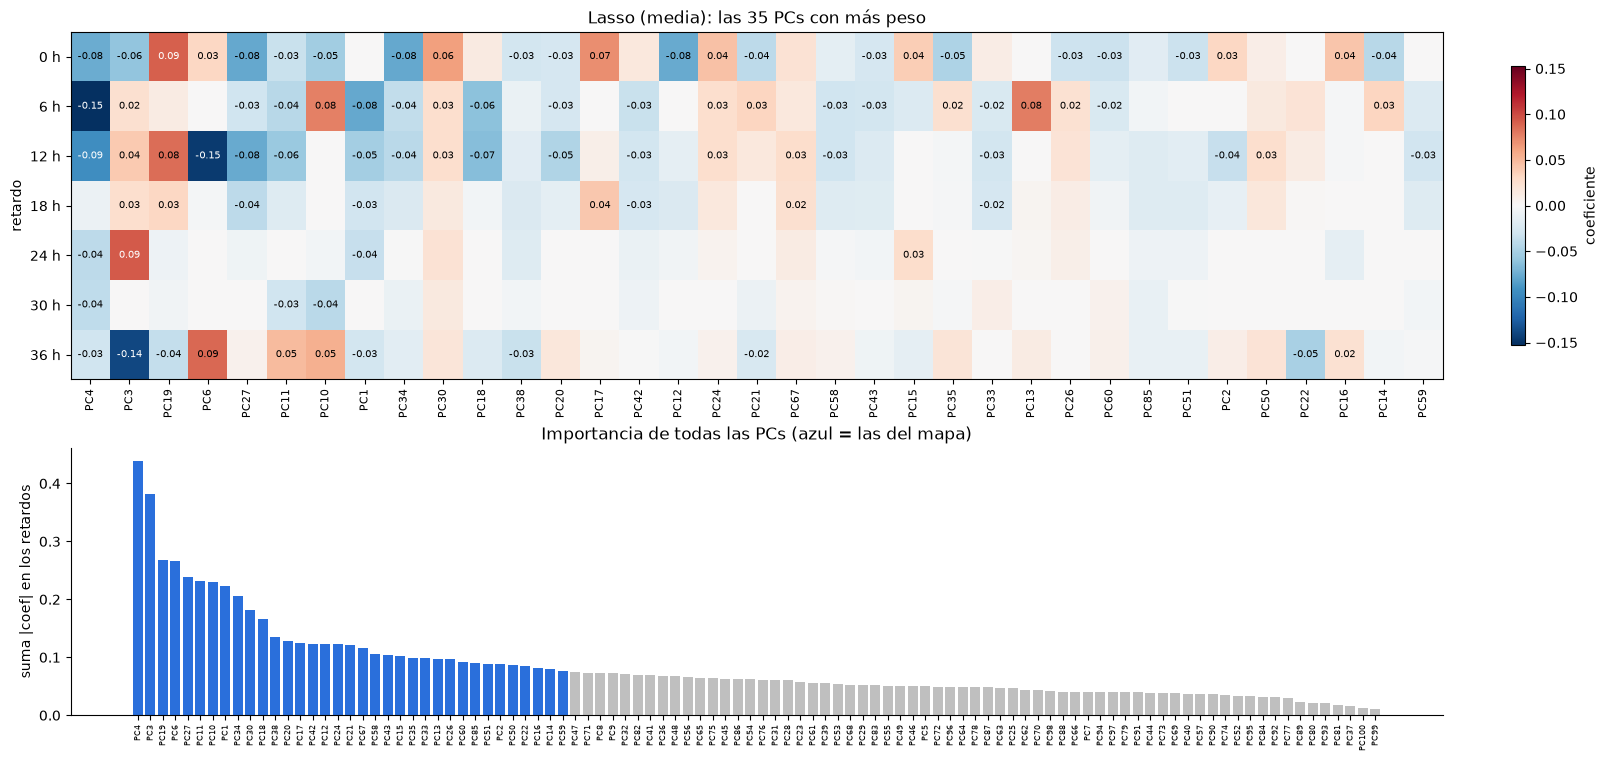

In [6]:
def matriz(coef):
    """coef por columna 'msl_PC4_l12' → tabla lag × PC y suma |coef| por PC (ordenada)."""
    M = pd.DataFrame({"pc": [c.rsplit("_l", 1)[0] for c in coef.index],
                      "lag": [int(c.rsplit("_l", 1)[1]) for c in coef.index], "coef": coef.values})
    M = M.pivot(index="lag", columns="pc", values="coef").sort_index()
    return M, M.abs().sum().sort_values(ascending=False)

def pinta_ranking(coef, titulo, N_TOP=35):
    M, imp = matriz(coef)
    Mt = M[imp.index[:N_TOP]]
    lim = np.abs(Mt.values).max()
    fig, ax = plt.subplots(2, 1, figsize=(16, 7.5), constrained_layout=True, gridspec_kw={"height_ratios": [1.3, 1]})
    im = ax[0].imshow(Mt.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    for i in range(Mt.shape[0]):
        for j in range(Mt.shape[1]):
            v = Mt.iloc[i, j]
            if abs(v) >= 0.15 * lim:
                ax[0].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 * lim else "black")
    ax[0].set_xticks(range(Mt.shape[1]), [c.replace("msl_", "") for c in Mt.columns], rotation=90, fontsize=8)
    ax[0].set_yticks(range(Mt.shape[0]), [f"{l} h" for l in Mt.index])
    ax[0].set(ylabel="retardo", title=f"{titulo}: las {N_TOP} PCs con más peso")
    fig.colorbar(im, ax=ax[0], shrink=0.8, label="coeficiente")
    ax[1].bar(range(len(imp)), imp.values, color=["#2a6fdb" if i < N_TOP else "0.75" for i in range(len(imp))])
    ax[1].set_xticks(range(len(imp)), [c.replace("msl_", "") for c in imp.index], rotation=90, fontsize=6)
    ax[1].set(ylabel="suma |coef| en los retardos", title="Importancia de todas las PCs (azul = las del mapa)")
    ax[1].spines[["top", "right"]].set_visible(False)
    plt.show()
    return imp

imp_lasso = pinta_ranking(coef_lasso, "Lasso (media)")

#### 1b. Ranking de la cola: regresión cuantílica (τ = 0,95) con L1, todas las horas

τ = 0.95, α = 0.001 | coef ≠ 0: 336 de 700 (76 s)
Si quedan casi todos los coeficientes: sube ALPHA_Q; si quedan muy pocos (< 30 PCs con algún lag): bájalo.


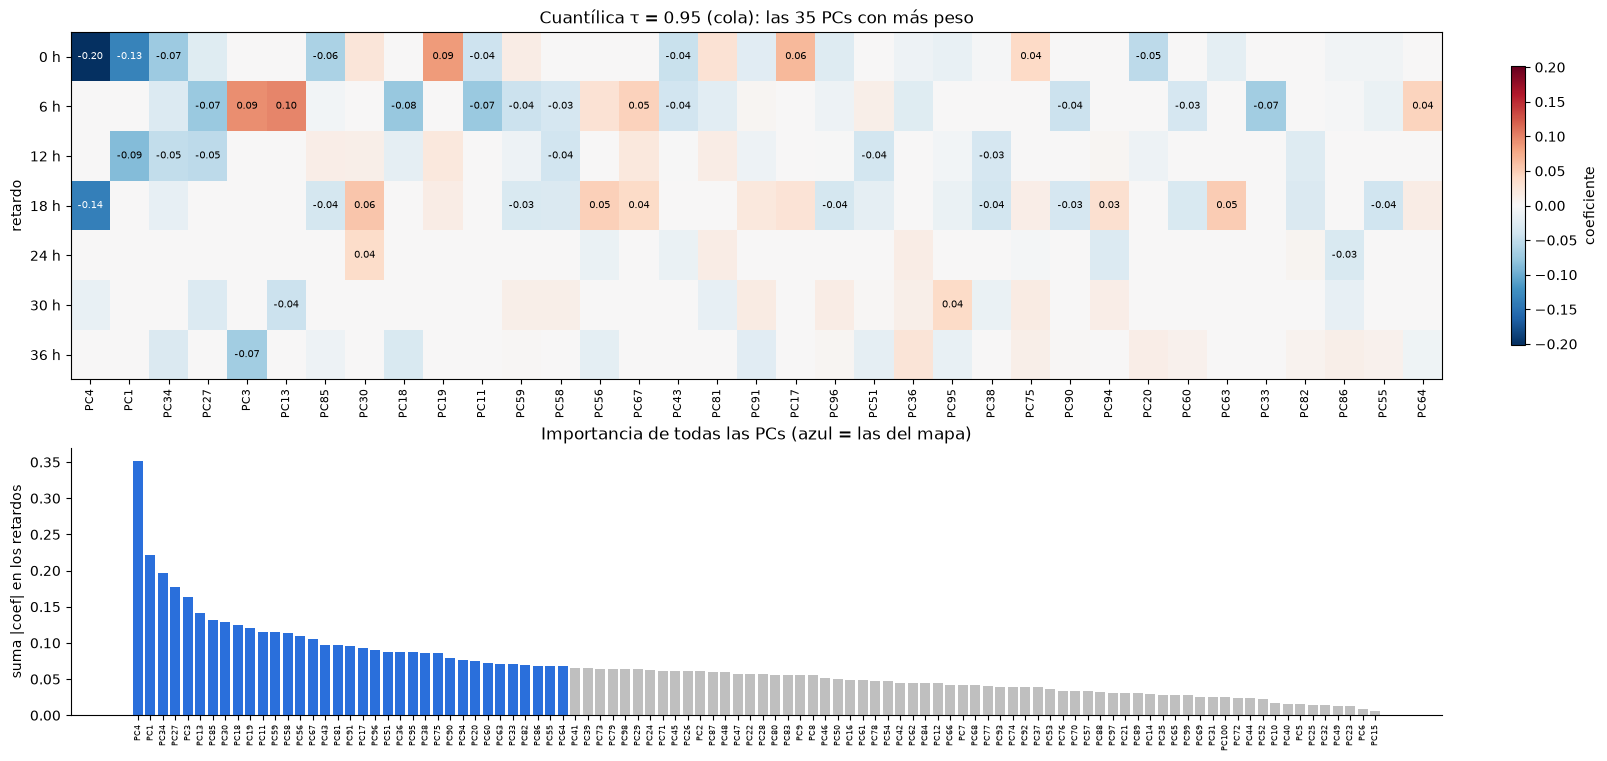

In [7]:
t = time.time()
qr = QuantileRegressor(quantile=TAU, alpha=ALPHA_Q, solver="highs").fit(Xs_tr[::PASO_Q], y_tr.values[::PASO_Q])
print(f"τ = {TAU}, α = {ALPHA_Q} | coef ≠ 0: {(qr.coef_ != 0).sum()} de {len(qr.coef_)} ({time.time() - t:.0f} s)")
print("Si quedan casi todos los coeficientes: sube ALPHA_Q; si quedan muy pocos (< 30 PCs con algún lag): bájalo.")
coef_q = pd.Series(qr.coef_, index=X_tr.columns)
imp_q = pinta_ranking(coef_q, f"Cuantílica τ = {TAU} (cola)")

#### 1c. ¿Eligen PCs distintas la media y la cola?

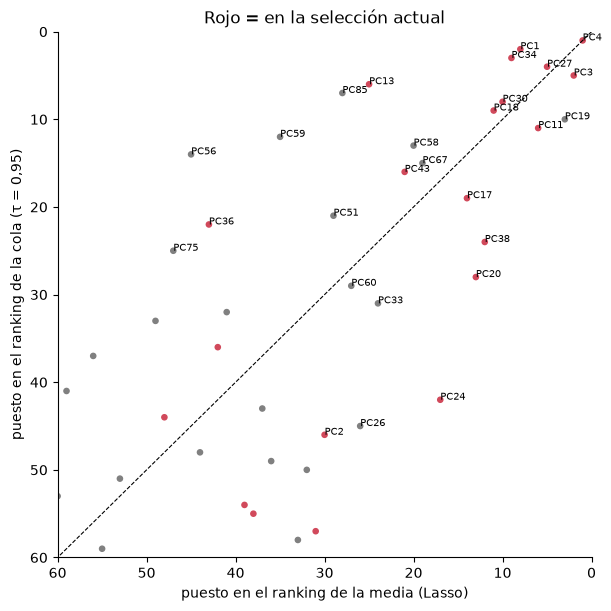

Suben más en la cola:
           puesto Lasso  puesto cuantílica  sube en la cola  en la selección actual
pc                                                                                
msl_PC81          97.0               17.0             80.0                   False
msl_PC95          90.0               23.0             67.0                   False
msl_PC91          81.0               18.0             63.0                   False
msl_PC90          87.0               26.0             61.0                   False
msl_PC94          78.0               27.0             51.0                   False
msl_PC96          66.0               20.0             46.0                   False
msl_PC73          83.0               38.0             45.0                   False
msl_PC80          95.0               52.0             43.0                   False
msl_PC79          80.0               39.0             41.0                   False
msl_PC63          70.0               30.0             40.0      

In [8]:
rk = pd.DataFrame({"puesto Lasso": imp_lasso.rank(ascending=False), "puesto cuantílica": imp_q.rank(ascending=False)}).fillna(len(imp_lasso))
rk["sube en la cola"] = rk["puesto Lasso"] - rk["puesto cuantílica"]
rk["en la selección actual"] = rk.index.isin(pcs_ref.columns)

fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)
ax.scatter(rk["puesto Lasso"], rk["puesto cuantílica"], s=14, c=np.where(rk["en la selección actual"], "#d1495b", "0.5"))
for pc, r in rk[(rk[["puesto Lasso", "puesto cuantílica"]].min(axis=1) <= 30)].iterrows():
    ax.annotate(pc.replace("msl_", ""), (r["puesto Lasso"], r["puesto cuantílica"]), fontsize=7)
ax.plot([0, 100], [0, 100], "k--", lw=0.8)
ax.set(xlabel="puesto en el ranking de la media (Lasso)", ylabel="puesto en el ranking de la cola (τ = 0,95)",
       title="Rojo = en la selección actual", xlim=(0, 60), ylim=(0, 60))
ax.invert_xaxis(); ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
plt.show()
print("Suben más en la cola:\n", rk.sort_values("sube en la cola", ascending=False).head(10).to_string())
print("\nBajan más en la cola:\n", rk.sort_values("sube en la cola").head(10).to_string())

#### 2. Curva de selección: XGB OOF (1985–2015) con las k primeras PCs de cada ranking
Métrica de temporales: picos observados de Hs (6 h) por encima del q99 de 1985–2015, separados 72 h; para cada uno, el máximo de ŷ en ±24 h dividido por el pico observado.

In [9]:
hs_tr = hs_desde_z(y_tr)
u99 = hs_tr.quantile(0.99)
t_picos = hs_tr.index[find_peaks(hs_tr.values, height=u99, distance=12)[0]]
print(f"{len(t_picos)} temporales en 1985–2015 (umbral {u99:.2f} m)")

def metricas_temporales(f, hs_obs, t_pk):
    h = hs_desde_z(f)
    w_ = pd.Timedelta("24h")
    ob = np.array([hs_obs.loc[t_] for t_ in t_pk])
    pk = np.array([h.loc[t_ - w_:t_ + w_].max() for t_ in t_pk])
    top = np.argsort(ob)[-10:]
    return {"pico ŷ/obs": np.mean(pk / ob), "pico ŷ/obs (10 mayores)": np.mean(pk[top] / ob[top]),
            "temporales < 0,7·obs (%)": 100 * np.mean(pk < 0.7 * ob)}

def oof(cols):
    f = pd.Series(np.nan, index=X_tr.index)
    for i_fit, i_val in cv_anos:
        m = XGBRegressor(**PAR).fit(X_tr.iloc[i_fit][cols], y_tr.iloc[i_fit])
        f.iloc[i_val] = m.predict(X_tr.iloc[i_val][cols])
    return f

def columnas(pcs):
    return [c_ for c_ in X_tr.columns if c_.rsplit("_l", 1)[0] in pcs]

curva = {}
for nom, imp in [("Lasso", imp_lasso), ("cuantílica", imp_q)]:
    for k in KS:
        t = time.time()
        f = oof(columnas(list(imp.index[:k])))
        curva[(nom, k)] = {"corr OOF": f.corr(y_tr), **metricas_temporales(f, hs_tr, t_picos)}
        print(f"{nom} k={k:3d}: corr {curva[(nom, k)]['corr OOF']:.3f} | pico {curva[(nom, k)]['pico ŷ/obs']:.3f} "
              f"| 10 mayores {curva[(nom, k)]['pico ŷ/obs (10 mayores)']:.3f} ({time.time() - t:.0f} s)", flush=True)
curva = pd.DataFrame(curva).T

154 temporales en 1985–2015 (umbral 3.72 m)
Lasso k=  5: corr 0.571 | pico 0.528 | 10 mayores 0.499 (10 s)
Lasso k= 10: corr 0.676 | pico 0.603 | 10 mayores 0.591 (19 s)
Lasso k= 15: corr 0.703 | pico 0.654 | 10 mayores 0.714 (30 s)
Lasso k= 20: corr 0.716 | pico 0.691 | 10 mayores 0.761 (43 s)
Lasso k= 25: corr 0.726 | pico 0.685 | 10 mayores 0.745 (56 s)
Lasso k= 30: corr 0.772 | pico 0.786 | 10 mayores 0.919 (68 s)
Lasso k= 40: corr 0.784 | pico 0.791 | 10 mayores 0.895 (95 s)
Lasso k= 50: corr 0.786 | pico 0.787 | 10 mayores 0.873 (122 s)
cuantílica k=  5: corr 0.609 | pico 0.524 | 10 mayores 0.539 (9 s)
cuantílica k= 10: corr 0.650 | pico 0.571 | 10 mayores 0.589 (20 s)
cuantílica k= 15: corr 0.681 | pico 0.619 | 10 mayores 0.632 (30 s)
cuantílica k= 20: corr 0.695 | pico 0.646 | 10 mayores 0.694 (41 s)
cuantílica k= 25: corr 0.707 | pico 0.664 | 10 mayores 0.723 (54 s)
cuantílica k= 30: corr 0.711 | pico 0.673 | 10 mayores 0.732 (67 s)
cuantílica k= 40: corr 0.720 | pico 0.679 | 

In [12]:
#### Selección actual en las mismas condiciones que la curva (OOF 1985–2015, mismos pliegues y temporales)
X_ref = lagged(pcs_ref.loc["1984-12-01":"2015-12-31"]).reindex(X_tr.index)
assert X_ref.notna().all().all(), "faltan PCs de referencia en alguna fila de entrenamiento"

f_ref = pd.Series(np.nan, index=X_tr.index)
t = time.time()
for i_fit, i_val in cv_anos:
    m = XGBRegressor(**PAR).fit(X_ref.iloc[i_fit], y_tr.iloc[i_fit])
    f_ref.iloc[i_val] = m.predict(X_ref.iloc[i_val])
ref = {"corr OOF": f_ref.corr(y_tr), **metricas_temporales(f_ref, hs_tr, t_picos)}
print(f"selección actual ({pcs_ref.shape[1]} PCs): " + " | ".join(f"{k_} {v:.3f}" for k_, v in ref.items()) + f" ({time.time() - t:.0f} s)")
print("Lasso 30:                  " + " | ".join(f"{k_} {v:.3f}" for k_, v in curva.loc[("Lasso", 30)].items()))

selección actual (30 PCs): corr OOF 0.785 | pico ŷ/obs 0.806 | pico ŷ/obs (10 mayores) 0.891 | temporales < 0,7·obs (%) 31.818 (66 s)
Lasso 30:                  corr OOF 0.772 | pico ŷ/obs 0.786 | pico ŷ/obs (10 mayores) 0.919 | temporales < 0,7·obs (%) 35.065


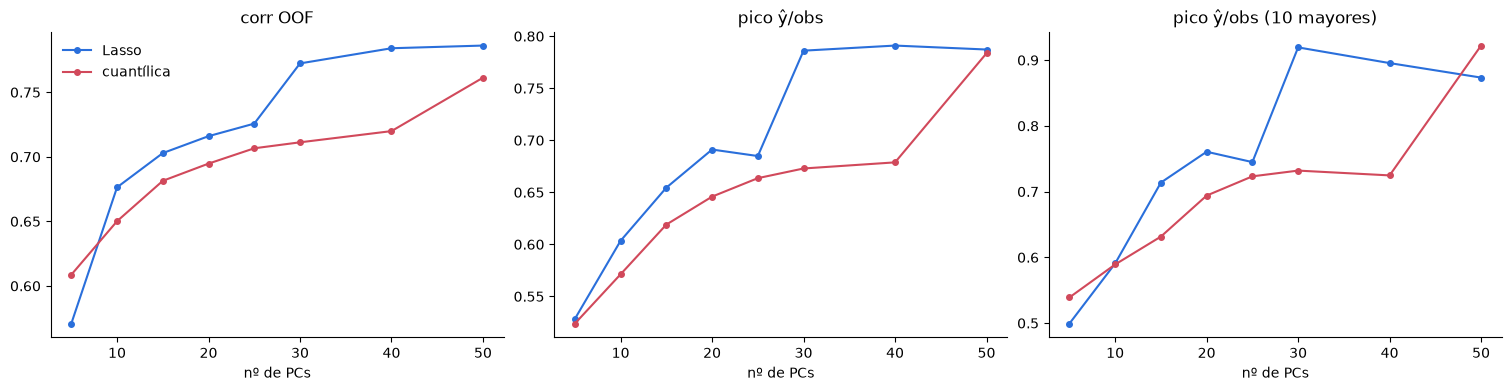

corr OOF  pico ŷ/obs  pico ŷ/obs (10 mayores)  \
Lasso      5      0.571       0.528                    0.499   
           10     0.676       0.603                    0.591   
           15     0.703       0.654                    0.714   
           20     0.716       0.691                    0.761   
           25     0.726       0.685                    0.745   
           30     0.772       0.786                    0.919   
           40     0.784       0.791                    0.895   
           50     0.786       0.787                    0.873   
cuantílica 5      0.609       0.524                    0.539   
           10     0.650       0.571                    0.589   
           15     0.681       0.619                    0.632   
           20     0.695       0.646                    0.694   
           25     0.707       0.664                    0.723   
           30     0.711       0.673                    0.732   
           40     0.720       0.679                    0.725   
           50     0.761       0.784                    0.922   

               temporales < 0,7·obs (%)  
Lasso      5                     87.662  
           10                    71.429  
           15                    62.338  
           20                    55.844  
           25                    53.247  
           30                    35.065  
           40                    34.416  
           50                    36.364  
cuantílica 5                     87.013  
           10                    79.221  
           15                    68.831  
           20                    61.039  
           25                    57.792  
           30                    58.442  
           40                    58.442  
           50                    32.468

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
for nom, col in [("Lasso", "#2a6fdb"), ("cuantílica", "#d1495b")]:
    c_ = curva.loc[nom]
    for a, m in zip(ax, ["corr OOF", "pico ŷ/obs", "pico ŷ/obs (10 mayores)"]):
        a.plot(c_.index, c_[m], "o-", color=col, ms=4, label=nom)
        a.set(xlabel="nº de PCs", title=m)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
ax[0].legend(frameon=False)
plt.show()
display(curva.round(3))

#### 3. Test 2016–2025: conjuntos elegidos vs selección actual
Elige K_LASSO y K_Q mirando la curva (pocas PCs, sin perder en temporales ni más de 0,01 de corr). Solo entonces se mira el test.

In [11]:
K_LASSO, K_Q = 30, 30                                        # ← según la curva
conjuntos = {"actual (referencia)": pcs_ref,
             f"Lasso {K_LASSO}": pcs_msl[list(imp_lasso.index[:K_LASSO])],
             f"cuantílica {K_Q}": pcs_msl[list(imp_q.index[:K_Q])],
             f"unión": pcs_msl[sorted(set(imp_lasso.index[:K_LASSO]) | set(imp_q.index[:K_Q]))]}

hs_te_obs = hs_desde_z(y_all[~tr])
t_picos_te = hs_te_obs.index[find_peaks(hs_te_obs.values, height=hs_te_obs.quantile(0.99), distance=12)[0]]
jul = slice("2023-02-25", "2023-03-03")
res = {}
for nom, P_ in conjuntos.items():
    Xc = lagged(P_.loc["1984-12-01":"2025-12-31"]).reindex(y_all.index).dropna()
    yc = y_all.loc[Xc.index]; trc = Xc.index < "2016-01-01"
    m = XGBRegressor(**PAR).fit(Xc[trc], yc[trc])
    f = pd.Series(m.predict(Xc[~trc]), index=Xc.index[~trc])
    res[nom] = {"nº PCs": P_.shape[1], "corr test": f.corr(yc[~trc]), **metricas_temporales(f, hs_te_obs, t_picos_te),
                "Juliette ŷ (m)": hs_desde_z(f).loc[jul].max()}
print(f"{len(t_picos_te)} temporales en test | Juliette obs (6 h): {hs_te_obs.loc[jul].max():.2f} m")
display(pd.DataFrame(res).T.round(3))

49 temporales en test | Juliette obs (6 h): 5.97 m


,nº PCs,corr test,pico ŷ/obs,pico ŷ/obs (10 mayores),"temporales < 0,7·obs (%)",Juliette ŷ (m)
actual (referencia),30.0,0.779,0.805,0.834,32.653,2.637
Lasso 30,30.0,0.769,0.789,0.831,36.735,2.436
cuantílica 30,30.0,0.703,0.688,0.776,53.061,3.366
unión,41.0,0.768,0.773,0.816,38.776,2.652
